Evaluación comparativa de modelos sequence-to-sequence para traducción inglés-español

Integrantes:

Ricardo Manuel Barbosa Flores - A00823815

Kevin Bolaños Borja - A00838335

Curso: Procesamiento de Lenguaje Natural — TC3009C


In [2]:
# Instalar dependencias necesarias para el proyecto.
%pip install -q "transformers>=5,<6" "huggingface-hub>=1.32,<2" sentencepiece sacrebleu jedi

# Revisar si hay conflictos entre paquetes.
%pip check

No broken requirements found.


In [4]:
import os
from google.colab import drive

# Conectar Google Drive
drive.mount("/content/drive")

# Carpeta donde se guardará el proyecto
SAVE_DIR = "/content/drive/MyDrive/Proyecto_NLP_NMT"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Carpeta del proyecto:", SAVE_DIR)

Mounted at /content/drive
Carpeta del proyecto: /content/drive/MyDrive/Proyecto_NLP_NMT


In [5]:
import os
import shutil

zip_path = os.path.join(SAVE_DIR, "spa-eng.zip")
data_path = os.path.join(SAVE_DIR, "spa.txt")

if not os.path.exists(data_path):
    print("Descargando el dataset...")

    # Descargar y descomprimir en el entorno de Colab
    !wget -q --show-progress https://www.manythings.org/anki/spa-eng.zip -O /content/spa-eng.zip
    !unzip -q -o /content/spa-eng.zip -d /content/dataset_nlp

    # Guardar una copia en Drive para reutilizarla
    if os.path.exists("/content/dataset_nlp/spa.txt"):
        shutil.copy2("/content/dataset_nlp/spa.txt", data_path)
        print("Dataset guardado en Drive.")
    else:
        print("No se pudo descargar o extraer el dataset.")
else:
    print("Se utilizará el dataset guardado en Drive.")

print("Ubicación:", data_path)

Se utilizará el dataset guardado en Drive.
Ubicación: /content/drive/MyDrive/Proyecto_NLP_NMT/spa.txt


In [7]:
import random
import hashlib

# 1. Leer pares inglés-español
with open(data_path, "r", encoding="utf-8") as f:
    raw_pairs = [
        line.strip().split("\t")[:2]
        for line in f
        if "\t" in line
    ]

# 2. Filtrado obligatorio
filtered_pairs = [
    (en, es)
    for en, es in raw_pairs
    if 8 <= len(en.split()) <= 120 and len(es.split()) <= 120
]

# 3. Mezcla determinista con semilla 23
rng = random.Random(23)
rng.shuffle(filtered_pairs)

# 4. Partición 80 % / 10 % / 10 %
n = len(filtered_pairs)
n_train = int(0.80 * n)
n_val = int(0.10 * n)

train_pairs = filtered_pairs[:n_train]
val_pairs = filtered_pairs[n_train:n_train + n_val]
test_pairs = filtered_pairs[n_train + n_val:]

# 5. Huella de auditoría obligatoria
test_hash = hashlib.sha256(
    "\n".join([p[0] for p in test_pairs]).encode()
).hexdigest()[:12]

print(f"Train: {len(train_pairs)}")
print(f"Validación: {len(val_pairs)}")
print(f"Test: {len(test_pairs)}")
print(f"SHA-256 Test Audit ID: {test_hash}")

# Revisar un ejemplo de entrenamiento
print("\nEjemplo de entrenamiento:")
print("Inglés:", train_pairs[0][0])
print("Español:", train_pairs[0][1])

Train: 29130
Validación: 3641
Test: 3642
SHA-256 Test Audit ID: dbac04ac5648

Ejemplo de entrenamiento:
Inglés: Pluto isn't the only known dwarf planet in our solar system.
Español: Plutón no es el único planeta enano conocido del Sistema Solar.


In [ ]:
import json

auditoria = {
    "train": len(train_pairs),
    "validation": len(val_pairs),
    "test": len(test_pairs),
    "test_audit_id": test_hash,
    "semilla": 23,
}

audit_path = os.path.join(SAVE_DIR, "auditoria_datos.json")

with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(auditoria, f, indent=2, ensure_ascii=False)

print("Auditoría guardada en:", audit_path)

Auditoría guardada en: /content/drive/MyDrive/Proyecto_NLP_NMT/auditoria_datos.json


In [ ]:
import json
import re
import unicodedata
from collections import Counter

# Tokens especiales. PAD debe tener el índice 0.
PAD = "<pad>"
UNK = "<unk>"
SOS = "<sos>"
EOS = "<eos>"

SPECIAL_TOKENS = [PAD, UNK, SOS, EOS]

def limpiar_texto(texto):
    """Minúsculas, sin acentos y sin signos de puntuación."""
    texto = texto.lower().strip()

    # Separar letras y acentos; después eliminar los acentos.
    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(
        caracter for caracter in texto
        if unicodedata.category(caracter) != "Mn"
    )

    # Conservar letras, números y espacios.
    texto = re.sub(r"[^\w\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

def crear_vocabulario(oraciones):
    """Construye un vocabulario a partir de las oraciones recibidas."""
    contador = Counter()

    for oracion in oraciones:
        contador.update(limpiar_texto(oracion).split())

    vocabulario = {
        token: indice
        for indice, token in enumerate(SPECIAL_TOKENS)
    }

    # Orden determinista para poder reconstruir los mismos índices.
    for palabra in sorted(contador):
        if palabra not in vocabulario:
            vocabulario[palabra] = len(vocabulario)

    return vocabulario

# Usamos exclusivamente train_pairs.
eng_word2idx = crear_vocabulario(en for en, es in train_pairs)
spa_word2idx = crear_vocabulario(es for en, es in train_pairs)

print("Vocabulario inglés:", len(eng_word2idx), "tokens")
print("Vocabulario español:", len(spa_word2idx), "tokens")
print("Índice de <pad>:", eng_word2idx[PAD], spa_word2idx[PAD])

# Guardar los vocabularios en Drive.
vocab_path = os.path.join(SAVE_DIR, "vocabularios.json")

with open(vocab_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "eng_word2idx": eng_word2idx,
            "spa_word2idx": spa_word2idx,
            "test_audit_id": test_hash,
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

print("Vocabularios guardados en:", vocab_path)

# Comprobación de la limpieza.
print("\nEjemplo de limpieza:")
print("Original:", train_pairs[0][1])
print("Limpio:  ", limpiar_texto(train_pairs[0][1]))

Vocabulario inglés: 8881 tokens
Vocabulario español: 15210 tokens
Índice de <pad>: 0 0
Vocabularios guardados en: /content/drive/MyDrive/Proyecto_NLP_NMT/vocabularios.json

Ejemplo de limpieza:
Original: Plutón no es el único planeta enano conocido del Sistema Solar.
Limpio:   pluton no es el unico planeta enano conocido del sistema solar


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("¿GPU disponible?", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Actualmente estás usando CPU.")

PyTorch: 2.14.1+cu130
¿GPU disponible? True
GPU: Tesla T4


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

# Usar la GPU disponible.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

# Índices de tokens especiales.
PAD_IDX = 0
UNK_IDX = 1
SOS_IDX = 2
EOS_IDX = 3

def convertir_a_indices(texto, vocabulario):
    """
    Limpia una oración y la convierte a números.
    Las palabras desconocidas se convierten a <unk>.
    """
    palabras = limpiar_texto(texto).split()

    indices = [SOS_IDX]
    indices += [
        vocabulario.get(palabra, UNK_IDX)
        for palabra in palabras
    ]
    indices += [EOS_IDX]

    return torch.tensor(indices, dtype=torch.long)


class DatasetTraduccion(Dataset):
    def __init__(self, pares, vocab_ing, vocab_esp):
        self.pares = pares
        self.vocab_ing = vocab_ing
        self.vocab_esp = vocab_esp

    def __len__(self):
        return len(self.pares)

    def __getitem__(self, indice):
        ingles, espanol = self.pares[indice]

        origen = convertir_a_indices(ingles, self.vocab_ing)
        destino = convertir_a_indices(espanol, self.vocab_esp)

        return origen, destino


def preparar_lote(ejemplos):
    """
    Rellena cada lote con <pad> hasta alcanzar
    la longitud de la oración más larga del lote.
    """
    origenes, destinos = zip(*ejemplos)

    origenes = pad_sequence(
        origenes,
        batch_first=True,
        padding_value=PAD_IDX
    )

    destinos = pad_sequence(
        destinos,
        batch_first=True,
        padding_value=PAD_IDX
    )

    return origenes, destinos


# Por ahora preparamos solo entrenamiento y validación.
train_dataset = DatasetTraduccion(
    train_pairs, eng_word2idx, spa_word2idx
)

val_dataset = DatasetTraduccion(
    val_pairs, eng_word2idx, spa_word2idx
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=preparar_lote
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=preparar_lote
)

# Comprobar un lote.
origen, destino = next(iter(train_loader))

print("Forma del lote en inglés:", origen.shape)
print("Forma del lote en español:", destino.shape)
print("Número de lotes de entrenamiento:", len(train_loader))
print("Número de lotes de validación:", len(val_loader))

Dispositivo: cuda
Forma del lote en inglés: torch.Size([32, 22])
Forma del lote en español: torch.Size([32, 20])
Número de lotes de entrenamiento: 911
Número de lotes de validación: 114


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Para que los resultados sean más fáciles de reproducir.
torch.manual_seed(23)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(23)


class EncoderBiLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, dropout):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        # La salida del encoder tiene tamaño hidden_dim * 2
        # porque la LSTM es bidireccional.
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, origen):
        # origen: [batch, longitud]
        mascara = origen != PAD_IDX
        longitudes = mascara.sum(dim=1).cpu()

        embeddings = self.dropout(self.embedding(origen))

        # Evita que la LSTM procese el padding como texto real.
        empaquetado = nn.utils.rnn.pack_padded_sequence(
            embeddings,
            longitudes,
            batch_first=True,
            enforce_sorted=False
        )

        salidas, (hidden, cell) = self.lstm(empaquetado)

        salidas, _ = nn.utils.rnn.pad_packed_sequence(
            salidas,
            batch_first=True,
            total_length=origen.size(1)
        )

        # Concatenar los estados de ambas direcciones.
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        cell = torch.cat((cell[-2], cell[-1]), dim=1)

        return salidas, hidden, cell, mascara


class DecoderAtencion(nn.Module):
    def __init__(self, vocab_size, embedding_dim, encoder_hidden, dropout):
        super().__init__()

        decoder_hidden = encoder_hidden * 2

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        self.lstm_cell = nn.LSTMCell(
            input_size=embedding_dim + decoder_hidden,
            hidden_size=decoder_hidden
        )

        self.salida = nn.Linear(
            decoder_hidden * 2,
            vocab_size
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, token, hidden, cell, salidas_encoder, mascara):
        # Atención por producto punto entre el estado actual
        # del decoder y todos los estados del encoder.
        scores = torch.bmm(
            salidas_encoder,
            hidden.unsqueeze(2)
        ).squeeze(2)

        # El padding no debe recibir atención.
        scores = scores.masked_fill(~mascara, float("-inf"))
        atencion = F.softmax(scores, dim=1)

        contexto = torch.bmm(
            atencion.unsqueeze(1),
            salidas_encoder
        ).squeeze(1)

        embedding = self.dropout(self.embedding(token))

        entrada_lstm = torch.cat((embedding, contexto), dim=1)
        hidden, cell = self.lstm_cell(entrada_lstm, (hidden, cell))

        logits = self.salida(torch.cat((hidden, contexto), dim=1))

        return logits, hidden, cell, atencion


class ModeloA(nn.Module):
    def __init__(
        self,
        vocab_ing_size,
        vocab_esp_size,
        embedding_dim=128,
        hidden_dim=128,
        dropout=0.1
    ):
        super().__init__()

        self.encoder = EncoderBiLSTM(
            vocab_ing_size, embedding_dim, hidden_dim, dropout
        )

        self.decoder = DecoderAtencion(
            vocab_esp_size, embedding_dim, hidden_dim, dropout
        )

    def forward(self, origen, destino):
        """
        Teacher forcing: el decoder recibe el token correcto anterior.
        Devuelve logits para predecir destino[:, 1:].
        """
        salidas_encoder, hidden, cell, mascara = self.encoder(origen)

        predicciones = []

        for paso in range(destino.size(1) - 1):
            token_actual = destino[:, paso]

            logits, hidden, cell, _ = self.decoder(
                token_actual,
                hidden,
                cell,
                salidas_encoder,
                mascara
            )

            predicciones.append(logits)

        return torch.stack(predicciones, dim=1)


modelo_a = ModeloA(
    vocab_ing_size=len(eng_word2idx),
    vocab_esp_size=len(spa_word2idx)
).to(device)

parametros_a = sum(
    parametro.numel()
    for parametro in modelo_a.parameters()
    if parametro.requires_grad
)

print(f"Modelo A creado en: {device}")
print(f"Parámetros entrenables: {parametros_a:,}")

Modelo A creado en: cuda
Parámetros entrenables: 11,807,978


In [ ]:
import os
import time
import math

criterio_a = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX,
    reduction="sum"
)

optimizador_a = torch.optim.Adam(
    modelo_a.parameters(),
    lr=0.001
)

history_a = {
    "train_loss": [],
    "val_loss": [],
    "tiempo_epoca_segundos": []
}

checkpoint_a = os.path.join(SAVE_DIR, "modelo_a_ultimo.pt")
mejor_checkpoint_a = os.path.join(SAVE_DIR, "modelo_a_mejor.pt")

epoca_inicial_a = 0
mejor_val_loss_a = float("inf")


def guardar_checkpoint_a(ruta, epoca, mejor_val_loss):
    """Guarda modelo, optimizador, historial y auditoría."""
    checkpoint = {
        "epoch": epoca,
        "model_state_dict": modelo_a.state_dict(),
        "optimizer_state_dict": optimizador_a.state_dict(),
        "history": history_a,
        "best_val_loss": mejor_val_loss,
        "test_audit_id": test_hash,
        "vocab_ing_size": len(eng_word2idx),
        "vocab_esp_size": len(spa_word2idx),
    }

    # Primero guardar en un archivo temporal para reducir el riesgo
    # de dejar incompleto el checkpoint anterior.
    ruta_temporal = ruta + ".tmp"
    torch.save(checkpoint, ruta_temporal)
    os.replace(ruta_temporal, ruta)


# Si ya existe un avance, recuperarlo automáticamente.
if os.path.exists(checkpoint_a):
    checkpoint = torch.load(
        checkpoint_a,
        map_location=device,
        weights_only=True
    )

    if checkpoint["test_audit_id"] != test_hash:
        raise ValueError(
            "La auditoría del checkpoint no coincide con los datos actuales."
        )

    if (
        checkpoint["vocab_ing_size"] != len(eng_word2idx)
        or checkpoint["vocab_esp_size"] != len(spa_word2idx)
    ):
        raise ValueError(
            "Los vocabularios actuales no coinciden con el checkpoint."
        )

    modelo_a.load_state_dict(checkpoint["model_state_dict"])
    optimizador_a.load_state_dict(checkpoint["optimizer_state_dict"])

    history_a = checkpoint["history"]
    epoca_inicial_a = checkpoint["epoch"]
    mejor_val_loss_a = checkpoint["best_val_loss"]

    print(f"Avance recuperado: {epoca_inicial_a} épocas completadas.")
else:
    print("No hay checkpoint anterior. El entrenamiento comenzará desde cero.")


def ejecutar_epoca_a(loader, entrenamiento=True):
    modelo_a.train(entrenamiento)

    perdida_total = 0.0
    tokens_totales = 0

    with torch.set_grad_enabled(entrenamiento):
        for origen, destino in loader:
            origen = origen.to(device)
            destino = destino.to(device)

            if entrenamiento:
                optimizador_a.zero_grad()

            logits = modelo_a(origen, destino)

            # Los logits predicen el siguiente token.
            etiquetas = destino[:, 1:]

            perdida_suma = criterio_a(
                logits.reshape(-1, logits.size(-1)),
                etiquetas.reshape(-1)
            )

            num_tokens = (etiquetas != PAD_IDX).sum()

            if entrenamiento:
                perdida = perdida_suma / num_tokens
                perdida.backward()

                # Ayuda a estabilizar el entrenamiento de la LSTM.
                nn.utils.clip_grad_norm_(modelo_a.parameters(), 1.0)
                optimizador_a.step()

            perdida_total += perdida_suma.item()
            tokens_totales += num_tokens.item()

    return perdida_total / tokens_totales


print("Entrenamiento y guardado configurados.")

No hay checkpoint anterior. El entrenamiento comenzará desde cero.
Entrenamiento y guardado configurados.


In [ ]:
# Total de épocas deseadas, no épocas adicionales.
EPOCAS_A = 5

for epoca in range(epoca_inicial_a, EPOCAS_A):
    inicio = time.perf_counter()

    train_loss = ejecutar_epoca_a(train_loader, entrenamiento=True)
    val_loss = ejecutar_epoca_a(val_loader, entrenamiento=False)

    tiempo_epoca = time.perf_counter() - inicio

    history_a["train_loss"].append(train_loss)
    history_a["val_loss"].append(val_loss)
    history_a["tiempo_epoca_segundos"].append(tiempo_epoca)

    es_mejor = val_loss < mejor_val_loss_a

    if es_mejor:
        mejor_val_loss_a = val_loss

    guardar_checkpoint_a(
        checkpoint_a,
        epoca=epoca + 1,
        mejor_val_loss=mejor_val_loss_a
    )

    if es_mejor:
        guardar_checkpoint_a(
            mejor_checkpoint_a,
            epoca=epoca + 1,
            mejor_val_loss=mejor_val_loss_a
        )

    print(
        f"Época {epoca + 1}/{EPOCAS_A} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Tiempo: {tiempo_epoca / 60:.1f} min"
        + (" | Mejor modelo guardado" if es_mejor else ""),
        flush=True
    )

print("\nEntrenamiento inicial del Modelo A terminado.")
print("Último checkpoint:", checkpoint_a)
print("Mejor checkpoint:", mejor_checkpoint_a)

Época 1/5 | Train loss: 5.0468 | Val loss: 3.9652 | Tiempo: 0.9 min | Mejor modelo guardado
Época 2/5 | Train loss: 3.3069 | Val loss: 3.2250 | Tiempo: 0.8 min | Mejor modelo guardado
Época 3/5 | Train loss: 2.4454 | Val loss: 2.9375 | Tiempo: 0.8 min | Mejor modelo guardado
Época 4/5 | Train loss: 1.9006 | Val loss: 2.8090 | Tiempo: 0.8 min | Mejor modelo guardado
Época 5/5 | Train loss: 1.5294 | Val loss: 2.7408 | Tiempo: 0.8 min | Mejor modelo guardado

Entrenamiento inicial del Modelo A terminado.
Último checkpoint: /content/drive/MyDrive/Proyecto_NLP_NMT/modelo_a_ultimo.pt
Mejor checkpoint: /content/drive/MyDrive/Proyecto_NLP_NMT/modelo_a_mejor.pt


In [ ]:
# Continuar desde la cantidad de épocas que ya están en el historial.
epoca_inicial_a = len(history_a["train_loss"])

# Queremos 10 épocas en total, no 10 adicionales.
EPOCAS_A = 10

for epoca in range(epoca_inicial_a, EPOCAS_A):
    inicio = time.perf_counter()

    train_loss = ejecutar_epoca_a(train_loader, entrenamiento=True)
    val_loss = ejecutar_epoca_a(val_loader, entrenamiento=False)

    tiempo_epoca = time.perf_counter() - inicio

    history_a["train_loss"].append(train_loss)
    history_a["val_loss"].append(val_loss)
    history_a["tiempo_epoca_segundos"].append(tiempo_epoca)

    es_mejor = val_loss < mejor_val_loss_a

    if es_mejor:
        mejor_val_loss_a = val_loss

    guardar_checkpoint_a(
        checkpoint_a,
        epoca=epoca + 1,
        mejor_val_loss=mejor_val_loss_a
    )

    if es_mejor:
        guardar_checkpoint_a(
            mejor_checkpoint_a,
            epoca=epoca + 1,
            mejor_val_loss=mejor_val_loss_a
        )

    print(
        f"Época {epoca + 1}/{EPOCAS_A} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Tiempo: {tiempo_epoca / 60:.1f} min"
        + (" | Mejor modelo guardado" if es_mejor else ""),
        flush=True
    )

print("\nÉpocas completadas:", len(history_a["train_loss"]))
print("Mejor pérdida de validación:", round(mejor_val_loss_a, 4))

Época 6/10 | Train loss: 1.2789 | Val loss: 2.7304 | Tiempo: 0.8 min | Mejor modelo guardado
Época 7/10 | Train loss: 1.1038 | Val loss: 2.7343 | Tiempo: 0.8 min
Época 8/10 | Train loss: 0.9708 | Val loss: 2.7469 | Tiempo: 0.8 min
Época 9/10 | Train loss: 0.8679 | Val loss: 2.7801 | Tiempo: 0.8 min
Época 10/10 | Train loss: 0.7827 | Val loss: 2.7926 | Tiempo: 0.8 min

Épocas completadas: 10
Mejor pérdida de validación: 2.7304


In [ ]:
import math
import copy
import torch
import torch.nn as nn


class PositionalEmbedding(nn.Module):
    def __init__(self, vocab_size, d_model, dropout=0.1, max_seq_len=1024):
        super().__init__()

        self.d_model = d_model

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD_IDX
        )

        self.dropout = nn.Dropout(dropout)

        # Codificación posicional sinusoidal.
        posiciones = torch.arange(
            max_seq_len, dtype=torch.float
        ).unsqueeze(1)

        frecuencias = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float)
            * (-math.log(10000.0) / d_model)
        )

        matriz = torch.zeros(max_seq_len, d_model)
        matriz[:, 0::2] = torch.sin(posiciones * frecuencias)
        matriz[:, 1::2] = torch.cos(posiciones * frecuencias)

        # Forma obligatoria: [1, max_seq_len, d_model].
        self.register_buffer("posiciones", matriz.unsqueeze(0))

    def forward(self, x):
        # x tiene forma [batch, longitud].
        if x.size(1) > self.posiciones.size(1):
            raise ValueError("La oración supera la longitud posicional máxima.")

        embeddings = self.embedding(x) * math.sqrt(self.d_model)

        # La posición se agrega sobre la dimensión temporal.
        embeddings = embeddings + self.posiciones[:, :x.size(1), :]

        return self.dropout(embeddings)


class CapaDecoder(nn.Module):
    """
    Capa de decoder que conserva la atención cruzada
    para visualizarla más adelante.
    """
    def __init__(self, d_model, num_heads, dff, dropout):
        super().__init__()

        self.self_attention = nn.MultiheadAttention(
            d_model, num_heads, dropout=dropout, batch_first=True
        )

        self.cross_attention = nn.MultiheadAttention(
            d_model, num_heads, dropout=dropout, batch_first=True
        )

        self.ffn = nn.Sequential(
            nn.Linear(d_model, dff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dff, d_model)
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

        self.ultima_atencion = None

    def forward(
        self,
        destino,
        memoria,
        mascara_futura,
        padding_destino,
        padding_origen,
        guardar_atencion=False
    ):
        # Autoatención causal del decoder.
        salida, _ = self.self_attention(
            destino,
            destino,
            destino,
            attn_mask=mascara_futura,
            key_padding_mask=padding_destino,
            need_weights=False
        )

        destino = self.norm1(destino + self.dropout1(salida))

        # Atención cruzada: salida del decoder frente al encoder.
        salida, pesos = self.cross_attention(
            destino,
            memoria,
            memoria,
            key_padding_mask=padding_origen,
            need_weights=guardar_atencion,
            average_attn_weights=False
        )

        self.ultima_atencion = (
            pesos.detach() if guardar_atencion else None
        )

        destino = self.norm2(destino + self.dropout2(salida))

        salida = self.ffn(destino)
        destino = self.norm3(destino + self.dropout3(salida))

        return destino


class TransformerTraduccion(nn.Module):
    def __init__(
        self,
        vocab_ing_size,
        vocab_esp_size,
        d_model=128,
        num_heads=4,
        dff=512,
        num_layers=2,
        dropout=0.1
    ):
        super().__init__()

        self.embedding_origen = PositionalEmbedding(
            vocab_ing_size, d_model, dropout
        )

        self.embedding_destino = PositionalEmbedding(
            vocab_esp_size, d_model, dropout
        )

        capa_encoder = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=dff,
            dropout=dropout,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            capa_encoder,
            num_layers=num_layers,
            enable_nested_tensor=False
        )

        self.decoders = nn.ModuleList([
            CapaDecoder(d_model, num_heads, dff, dropout)
            for _ in range(num_layers)
        ])

        self.salida = nn.Linear(d_model, vocab_esp_size)

    def forward(self, origen, destino, guardar_atencion=False):
        padding_origen = origen == PAD_IDX
        padding_destino = destino == PAD_IDX

        # True significa que esa posición futura está bloqueada.
        longitud = destino.size(1)
        mascara_futura = torch.triu(
            torch.ones(
                longitud, longitud,
                device=destino.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        memoria = self.encoder(
            self.embedding_origen(origen),
            src_key_padding_mask=padding_origen
        )

        salida = self.embedding_destino(destino)

        for capa in self.decoders:
            salida = capa(
                salida,
                memoria,
                mascara_futura,
                padding_destino,
                padding_origen,
                guardar_atencion=guardar_atencion
            )

        return self.salida(salida)


torch.manual_seed(23)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(23)

modelo_b = TransformerTraduccion(
    vocab_ing_size=len(eng_word2idx),
    vocab_esp_size=len(spa_word2idx),
    d_model=128,
    num_heads=4,
    dff=512,
    num_layers=2,
    dropout=0.1
).to(device)

parametros_b = sum(
    p.numel() for p in modelo_b.parameters() if p.requires_grad
)

print("Modelo B creado en:", device)
print(f"Parámetros entrenables: {parametros_b:,}")
print(
    "Forma de la matriz posicional:",
    modelo_b.embedding_origen.posiciones.shape
)

Modelo B creado en: cuda
Parámetros entrenables: 5,971,434
Forma de la matriz posicional: torch.Size([1, 1024, 128])


In [ ]:
import os
import time

criterio_b = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX,
    reduction="sum"
)

optimizador_b = torch.optim.Adam(
    modelo_b.parameters(),
    lr=0.0001
)

history_b = {
    "train_loss": [],
    "val_loss": [],
    "tiempo_epoca_segundos": []
}

checkpoint_b = os.path.join(SAVE_DIR, "modelo_b_ultimo.pt")
mejor_checkpoint_b = os.path.join(SAVE_DIR, "modelo_b_mejor.pt")

epoca_inicial_b = 0
mejor_val_loss_b = float("inf")


def guardar_checkpoint_b(ruta, epoca, mejor_val_loss):
    checkpoint = {
        "epoch": epoca,
        "model_state_dict": modelo_b.state_dict(),
        "optimizer_state_dict": optimizador_b.state_dict(),
        "history": history_b,
        "best_val_loss": mejor_val_loss,
        "test_audit_id": test_hash,
        "vocab_ing_size": len(eng_word2idx),
        "vocab_esp_size": len(spa_word2idx),
    }

    ruta_temporal = ruta + ".tmp"
    torch.save(checkpoint, ruta_temporal)
    os.replace(ruta_temporal, ruta)


if os.path.exists(checkpoint_b):
    checkpoint = torch.load(
        checkpoint_b,
        map_location=device,
        weights_only=True
    )

    if checkpoint["test_audit_id"] != test_hash:
        raise ValueError(
            "La auditoría del checkpoint no coincide con los datos actuales."
        )

    if (
        checkpoint["vocab_ing_size"] != len(eng_word2idx)
        or checkpoint["vocab_esp_size"] != len(spa_word2idx)
    ):
        raise ValueError(
            "Los vocabularios no coinciden con el checkpoint."
        )

    modelo_b.load_state_dict(checkpoint["model_state_dict"])
    optimizador_b.load_state_dict(checkpoint["optimizer_state_dict"])

    history_b = checkpoint["history"]
    epoca_inicial_b = checkpoint["epoch"]
    mejor_val_loss_b = checkpoint["best_val_loss"]

    print(f"Avance recuperado: {epoca_inicial_b} épocas completadas.")
else:
    print("El Modelo B comenzará desde cero.")


def ejecutar_epoca_b(loader, entrenamiento=True):
    modelo_b.train(entrenamiento)

    perdida_total = 0.0
    tokens_totales = 0

    with torch.set_grad_enabled(entrenamiento):
        for origen, destino in loader:
            origen = origen.to(device)
            destino = destino.to(device)

            if entrenamiento:
                optimizador_b.zero_grad()

            # El decoder recibe todos los tokens salvo el último.
            entrada_decoder = destino[:, :-1]

            # Debe predecir el siguiente token.
            etiquetas = destino[:, 1:]

            logits = modelo_b(origen, entrada_decoder)

            perdida_suma = criterio_b(
                logits.reshape(-1, logits.size(-1)),
                etiquetas.reshape(-1)
            )

            num_tokens = (etiquetas != PAD_IDX).sum()

            if entrenamiento:
                perdida = perdida_suma / num_tokens
                perdida.backward()

                nn.utils.clip_grad_norm_(
                    modelo_b.parameters(),
                    max_norm=1.0
                )

                optimizador_b.step()

            perdida_total += perdida_suma.item()
            tokens_totales += num_tokens.item()

    return perdida_total / tokens_totales


print("Entrenamiento del Modelo B configurado.")

El Modelo B comenzará desde cero.
Entrenamiento del Modelo B configurado.


In [ ]:
EPOCAS_B = 30
#Modificado de 10 a 30 por baja en perdida de validacion
# Si se vuelve a ejecutar esta celda en la misma sesión,
# continuar desde las épocas ya registradas.
epoca_inicial_b = len(history_b["train_loss"])

for epoca in range(epoca_inicial_b, EPOCAS_B):
    inicio = time.perf_counter()

    train_loss = ejecutar_epoca_b(
        train_loader,
        entrenamiento=True
    )

    val_loss = ejecutar_epoca_b(
        val_loader,
        entrenamiento=False
    )

    tiempo_epoca = time.perf_counter() - inicio

    history_b["train_loss"].append(train_loss)
    history_b["val_loss"].append(val_loss)
    history_b["tiempo_epoca_segundos"].append(tiempo_epoca)

    es_mejor = val_loss < mejor_val_loss_b

    if es_mejor:
        mejor_val_loss_b = val_loss

    guardar_checkpoint_b(
        checkpoint_b,
        epoca=epoca + 1,
        mejor_val_loss=mejor_val_loss_b
    )

    if es_mejor:
        guardar_checkpoint_b(
            mejor_checkpoint_b,
            epoca=epoca + 1,
            mejor_val_loss=mejor_val_loss_b
        )

    print(
        f"Época {epoca + 1}/{EPOCAS_B} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Tiempo: {tiempo_epoca / 60:.1f} min"
        + (" | Mejor modelo guardado" if es_mejor else ""),
        flush=True
    )

print("\nEntrenamiento inicial del Modelo B terminado.")
print("Mejor pérdida de validación:", round(mejor_val_loss_b, 4))
print("Mejor checkpoint:", mejor_checkpoint_b)

Época 11/30 | Train loss: 3.7101 | Val loss: 3.8712 | Tiempo: 0.4 min | Mejor modelo guardado
Época 12/30 | Train loss: 3.5987 | Val loss: 3.7976 | Tiempo: 0.4 min | Mejor modelo guardado
Época 13/30 | Train loss: 3.4946 | Val loss: 3.7185 | Tiempo: 0.4 min | Mejor modelo guardado
Época 14/30 | Train loss: 3.3974 | Val loss: 3.6741 | Tiempo: 0.4 min | Mejor modelo guardado
Época 15/30 | Train loss: 3.3065 | Val loss: 3.6105 | Tiempo: 0.4 min | Mejor modelo guardado
Época 16/30 | Train loss: 3.2171 | Val loss: 3.5709 | Tiempo: 0.4 min | Mejor modelo guardado
Época 17/30 | Train loss: 3.1351 | Val loss: 3.5125 | Tiempo: 0.4 min | Mejor modelo guardado
Época 18/30 | Train loss: 3.0558 | Val loss: 3.4759 | Tiempo: 0.4 min | Mejor modelo guardado
Época 19/30 | Train loss: 2.9816 | Val loss: 3.4433 | Tiempo: 0.4 min | Mejor modelo guardado
Época 20/30 | Train loss: 2.9107 | Val loss: 3.4123 | Tiempo: 0.4 min | Mejor modelo guardado
Época 21/30 | Train loss: 2.8383 | Val loss: 3.3824 | Tiempo

In [ ]:
# Continuar desde la última época registrada.
EPOCAS_MAX_B = 60
PACIENCIA_B = 5

# Contar las épocas consecutivas sin mejora.
mejor_hasta_ahora = float("inf")
sin_mejora_b = 0

for perdida in history_b["val_loss"]:
    if perdida < mejor_hasta_ahora:
        mejor_hasta_ahora = perdida
        sin_mejora_b = 0
    else:
        sin_mejora_b += 1

epoca_inicial_b = len(history_b["train_loss"])

for epoca in range(epoca_inicial_b, EPOCAS_MAX_B):
    if sin_mejora_b >= PACIENCIA_B:
        print("La paciencia ya se agotó. Se conserva el mejor checkpoint.")
        break

    inicio = time.perf_counter()

    train_loss = ejecutar_epoca_b(
        train_loader,
        entrenamiento=True
    )

    val_loss = ejecutar_epoca_b(
        val_loader,
        entrenamiento=False
    )

    tiempo_epoca = time.perf_counter() - inicio

    history_b["train_loss"].append(train_loss)
    history_b["val_loss"].append(val_loss)
    history_b["tiempo_epoca_segundos"].append(tiempo_epoca)

    es_mejor = val_loss < mejor_val_loss_b

    if es_mejor:
        mejor_val_loss_b = val_loss
        sin_mejora_b = 0
    else:
        sin_mejora_b += 1

    guardar_checkpoint_b(
        checkpoint_b,
        epoca=epoca + 1,
        mejor_val_loss=mejor_val_loss_b
    )

    if es_mejor:
        guardar_checkpoint_b(
            mejor_checkpoint_b,
            epoca=epoca + 1,
            mejor_val_loss=mejor_val_loss_b
        )

    print(
        f"Época {epoca + 1}/{EPOCAS_MAX_B} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Tiempo: {tiempo_epoca / 60:.1f} min | "
        f"Sin mejora: {sin_mejora_b}/{PACIENCIA_B}"
        + (" | Mejor modelo guardado" if es_mejor else ""),
        flush=True
    )

mejor_epoca_b = (
    min(
        range(len(history_b["val_loss"])),
        key=lambda i: history_b["val_loss"][i]
    ) + 1
)

print("\nEntrenamiento del Modelo B terminado.")
print("Épocas completadas:", len(history_b["train_loss"]))
print("Mejor época:", mejor_epoca_b)
print("Mejor pérdida de validación:", round(mejor_val_loss_b, 4))
print("Mejor checkpoint:", mejor_checkpoint_b)

Época 31/60 | Train loss: 2.2850 | Val loss: 3.1787 | Tiempo: 0.4 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 32/60 | Train loss: 2.2379 | Val loss: 3.1672 | Tiempo: 0.4 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 33/60 | Train loss: 2.1956 | Val loss: 3.1589 | Tiempo: 0.4 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 34/60 | Train loss: 2.1540 | Val loss: 3.1475 | Tiempo: 0.4 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 35/60 | Train loss: 2.1152 | Val loss: 3.1432 | Tiempo: 0.4 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 36/60 | Train loss: 2.0802 | Val loss: 3.1417 | Tiempo: 0.4 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 37/60 | Train loss: 2.0412 | Val loss: 3.1313 | Tiempo: 0.4 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 38/60 | Train loss: 2.0099 | Val loss: 3.1247 | Tiempo: 0.4 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 39/60 | Train loss: 1.9719 | Val loss: 3.1274 | Tiempo: 0.4 min | Sin mejora: 1/5
Época 40/60 | Tr

In [ ]:
import gc

# Los modelos A y B ya están guardados; liberamos su memoria de GPU.
modelo_a.to("cpu")
modelo_b.to("cpu")

# Mover también los estados de sus optimizadores a CPU.
for optimizador in (optimizador_a, optimizador_b):
    for estado in optimizador.state.values():
        for clave, valor in estado.items():
            if isinstance(valor, torch.Tensor):
                estado[clave] = valor.cpu()

gc.collect()
torch.cuda.empty_cache()

torch.manual_seed(23)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(23)

# Configuración obligatoria del Transformer de alta capacidad.
modelo_c = TransformerTraduccion(
    vocab_ing_size=len(eng_word2idx),
    vocab_esp_size=len(spa_word2idx),
    d_model=512,
    num_heads=8,
    dff=2048,
    num_layers=6,
    dropout=0.1
).to(device)

parametros_c = sum(
    p.numel() for p in modelo_c.parameters() if p.requires_grad
)

print("Modelo C creado en:", device)
print(f"Parámetros entrenables: {parametros_c:,}")
print(
    "Forma posicional:",
    modelo_c.embedding_origen.posiciones.shape
)

Modelo C creado en: cuda
Parámetros entrenables: 64,275,818
Forma posicional: torch.Size([1, 1024, 512])


In [ ]:
# Lotes más pequeños para reducir el uso de memoria de GPU.
BATCH_SIZE_C = 8

train_loader_c = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE_C,
    shuffle=True,
    collate_fn=preparar_lote
)

val_loader_c = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE_C,
    shuffle=False,
    collate_fn=preparar_lote
)

criterio_c = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX,
    reduction="sum"
)

# Tasa de aprendizaje requerida para el Modelo C.
optimizador_c = torch.optim.Adam(
    modelo_c.parameters(),
    lr=0.0001
)

history_c = {
    "train_loss": [],
    "val_loss": [],
    "tiempo_epoca_segundos": []
}

checkpoint_c = os.path.join(SAVE_DIR, "modelo_c_ultimo.pt")
mejor_checkpoint_c = os.path.join(SAVE_DIR, "modelo_c_mejor.pt")

mejor_val_loss_c = float("inf")


def guardar_checkpoint_c(ruta, epoca, mejor_val_loss):
    checkpoint = {
        "epoch": epoca,
        "model_state_dict": modelo_c.state_dict(),
        "optimizer_state_dict": optimizador_c.state_dict(),
        "history": history_c,
        "best_val_loss": mejor_val_loss,
        "test_audit_id": test_hash,
        "vocab_ing_size": len(eng_word2idx),
        "vocab_esp_size": len(spa_word2idx),
    }

    ruta_temporal = ruta + ".tmp"
    torch.save(checkpoint, ruta_temporal)
    os.replace(ruta_temporal, ruta)


if os.path.exists(checkpoint_c):
    checkpoint = torch.load(
        checkpoint_c,
        map_location=device,
        weights_only=True
    )

    if checkpoint["test_audit_id"] != test_hash:
        raise ValueError(
            "La auditoría del checkpoint no coincide con los datos."
        )

    if (
        checkpoint["vocab_ing_size"] != len(eng_word2idx)
        or checkpoint["vocab_esp_size"] != len(spa_word2idx)
    ):
        raise ValueError(
            "Los vocabularios no coinciden con el checkpoint."
        )

    modelo_c.load_state_dict(checkpoint["model_state_dict"])
    optimizador_c.load_state_dict(checkpoint["optimizer_state_dict"])

    history_c = checkpoint["history"]
    mejor_val_loss_c = checkpoint["best_val_loss"]

    print(
        "Avance recuperado:",
        checkpoint["epoch"],
        "épocas completadas."
    )
else:
    print("El Modelo C comenzará desde cero.")


def ejecutar_epoca_c(loader, entrenamiento=True):
    modelo_c.train(entrenamiento)

    perdida_total = 0.0
    tokens_totales = 0

    with torch.set_grad_enabled(entrenamiento):
        for origen, destino in loader:
            origen = origen.to(device)
            destino = destino.to(device)

            if entrenamiento:
                optimizador_c.zero_grad()

            entrada_decoder = destino[:, :-1]
            etiquetas = destino[:, 1:]

            logits = modelo_c(origen, entrada_decoder)

            perdida_suma = criterio_c(
                logits.reshape(-1, logits.size(-1)),
                etiquetas.reshape(-1)
            )

            num_tokens = (etiquetas != PAD_IDX).sum()

            if entrenamiento:
                perdida = perdida_suma / num_tokens
                perdida.backward()

                nn.utils.clip_grad_norm_(
                    modelo_c.parameters(),
                    max_norm=1.0
                )

                optimizador_c.step()

            perdida_total += perdida_suma.item()
            tokens_totales += num_tokens.item()

    return perdida_total / tokens_totales


print("Entrenamiento del Modelo C configurado.")

El Modelo C comenzará desde cero.
Entrenamiento del Modelo C configurado.


In [ ]:
EPOCAS_MAX_C = 15
PACIENCIA_C = 5

# Reconstruir cuántas épocas consecutivas van sin mejora.
mejor_hasta_ahora = float("inf")
sin_mejora_c = 0

for perdida in history_c["val_loss"]:
    if perdida < mejor_hasta_ahora:
        mejor_hasta_ahora = perdida
        sin_mejora_c = 0
    else:
        sin_mejora_c += 1

epoca_inicial_c = len(history_c["train_loss"])

for epoca in range(epoca_inicial_c, EPOCAS_MAX_C):
    if sin_mejora_c >= PACIENCIA_C:
        print("Se agotó la paciencia. Se conserva el mejor checkpoint.")
        break

    inicio = time.perf_counter()

    train_loss = ejecutar_epoca_c(
        train_loader_c,
        entrenamiento=True
    )

    val_loss = ejecutar_epoca_c(
        val_loader_c,
        entrenamiento=False
    )

    tiempo_epoca = time.perf_counter() - inicio

    history_c["train_loss"].append(train_loss)
    history_c["val_loss"].append(val_loss)
    history_c["tiempo_epoca_segundos"].append(tiempo_epoca)

    es_mejor = val_loss < mejor_val_loss_c

    if es_mejor:
        mejor_val_loss_c = val_loss
        sin_mejora_c = 0
    else:
        sin_mejora_c += 1

    guardar_checkpoint_c(
        checkpoint_c,
        epoca=epoca + 1,
        mejor_val_loss=mejor_val_loss_c
    )

    if es_mejor:
        guardar_checkpoint_c(
            mejor_checkpoint_c,
            epoca=epoca + 1,
            mejor_val_loss=mejor_val_loss_c
        )

    print(
        f"Época {epoca + 1}/{EPOCAS_MAX_C} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Tiempo: {tiempo_epoca / 60:.1f} min | "
        f"Sin mejora: {sin_mejora_c}/{PACIENCIA_C}"
        + (" | Mejor modelo guardado" if es_mejor else ""),
        flush=True
    )

if history_c["val_loss"]:
    mejor_epoca_c = min(
        range(len(history_c["val_loss"])),
        key=lambda i: history_c["val_loss"][i]
    ) + 1

    print("\nÉpocas completadas:", len(history_c["train_loss"]))
    print("Mejor época:", mejor_epoca_c)
    print("Mejor pérdida de validación:", round(mejor_val_loss_c, 4))
    print("Mejor checkpoint:", mejor_checkpoint_c)

Época 1/15 | Train loss: 5.0233 | Val loss: 4.2101 | Tiempo: 4.3 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 2/15 | Train loss: 3.7531 | Val loss: 3.5542 | Tiempo: 4.4 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 3/15 | Train loss: 3.0430 | Val loss: 3.0891 | Tiempo: 4.8 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 4/15 | Train loss: 2.5272 | Val loss: 2.8837 | Tiempo: 4.9 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 5/15 | Train loss: 2.1260 | Val loss: 2.7085 | Tiempo: 4.8 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 6/15 | Train loss: 1.7901 | Val loss: 2.5888 | Tiempo: 4.8 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 7/15 | Train loss: 1.5100 | Val loss: 2.5681 | Tiempo: 4.9 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 8/15 | Train loss: 1.2722 | Val loss: 2.5465 | Tiempo: 4.7 min | Sin mejora: 0/5 | Mejor modelo guardado
Época 9/15 | Train loss: 1.0678 | Val loss: 2.5587 | Tiempo: 4.8 min | Sin mejora: 1/5
Época 10/15 | Train loss:

In [ ]:
import gc
import torch

# El Modelo C y su optimizador ya están guardados en Drive.
# Liberamos la memoria que ocupan en GPU.
modelo_c.to("cpu")

for estado in optimizador_c.state.values():
    for clave, valor in estado.items():
        if isinstance(valor, torch.Tensor):
            estado[clave] = valor.cpu()

gc.collect()
torch.cuda.empty_cache()

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

NOMBRE_MODELO_D = "Helsinki-NLP/opus-mt-en-es"

print("Descargando tokenizador y modelo preentrenado...")

tokenizer_d = AutoTokenizer.from_pretrained(NOMBRE_MODELO_D)

modelo_d = AutoModelForSeq2SeqLM.from_pretrained(
    NOMBRE_MODELO_D
).to(device)

parametros_d = sum(
    parametro.numel()
    for parametro in modelo_d.parameters()
    if parametro.requires_grad
)

print("\nModelo D cargado en:", device)
print(f"Parámetros entrenables: {parametros_d:,}")

# Prueba rápida antes del ajuste fino.
texto_prueba = "The weather is beautiful today."

entradas = tokenizer_d(
    texto_prueba,
    return_tensors="pt"
).to(device)

modelo_d.eval()

with torch.no_grad():
    salida = modelo_d.generate(**entradas, max_new_tokens=64)

traduccion = tokenizer_d.decode(
    salida[0],
    skip_special_tokens=True
)

print("\nPrueba del modelo preentrenado:")
print("Inglés:", texto_prueba)
print("Español:", traduccion)

Descargando tokenizador y modelo preentrenado...


config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Modelo D cargado en: cuda
Parámetros entrenables: 77,943,296

Prueba del modelo preentrenado:
Inglés: The weather is beautiful today.
Español: El tiempo es hermoso hoy.


In [ ]:
from torch.utils.data import Dataset, DataLoader

class DatasetModeloD(Dataset):
    def __init__(self, pares, tokenizer):
        ingles = [en for en, es in pares]
        espanol = [es for en, es in pares]

        # Sin truncamiento silencioso.
        entradas = tokenizer(
            ingles,
            padding=False,
            truncation=False
        )

        salidas = tokenizer(
            text_target=espanol,
            padding=False,
            truncation=False
        )

        self.entradas = entradas["input_ids"]
        self.salidas = salidas["input_ids"]

    def __len__(self):
        return len(self.entradas)

    def __getitem__(self, indice):
        return {
            "input_ids": self.entradas[indice],
            "labels": self.salidas[indice]
        }


def preparar_lote_d(ejemplos):
    # Padding dinámico para las oraciones de entrada.
    entradas = tokenizer_d.pad(
        [{"input_ids": e["input_ids"]} for e in ejemplos],
        padding=True,
        return_tensors="pt"
    )

    # -100 hace que la pérdida ignore el padding de las etiquetas.
    etiquetas = [
        torch.tensor(e["labels"], dtype=torch.long)
        for e in ejemplos
    ]

    entradas["labels"] = pad_sequence(
        etiquetas,
        batch_first=True,
        padding_value=-100
    )

    return entradas


print("Preparando entrenamiento...")
train_dataset_d = DatasetModeloD(train_pairs, tokenizer_d)

print("Preparando validación...")
val_dataset_d = DatasetModeloD(val_pairs, tokenizer_d)

# Comprobar que las secuencias caben en el modelo.
longitud_maxima_d = max(
    max(len(x) for x in train_dataset_d.entradas),
    max(len(x) for x in train_dataset_d.salidas),
    max(len(x) for x in val_dataset_d.entradas),
    max(len(x) for x in val_dataset_d.salidas)
)

limite_modelo_d = modelo_d.config.max_position_embeddings

print("Longitud máxima encontrada:", longitud_maxima_d)
print("Límite de posiciones del modelo:", limite_modelo_d)

if longitud_maxima_d > limite_modelo_d:
    raise ValueError(
        "Hay secuencias más largas que el límite del modelo. "
        "Compárteme esta salida antes de continuar."
    )

BATCH_SIZE_D = 8

train_loader_d = DataLoader(
    train_dataset_d,
    batch_size=BATCH_SIZE_D,
    shuffle=True,
    collate_fn=preparar_lote_d
)

val_loader_d = DataLoader(
    val_dataset_d,
    batch_size=BATCH_SIZE_D,
    shuffle=False,
    collate_fn=preparar_lote_d
)

print("Lotes de entrenamiento:", len(train_loader_d))
print("Lotes de validación:", len(val_loader_d))
print("Datos listos para el Modelo D.")

Preparando entrenamiento...
Preparando validación...
Longitud máxima encontrada: 85
Límite de posiciones del modelo: 512
Lotes de entrenamiento: 3642
Lotes de validación: 456
Datos listos para el Modelo D.


In [ ]:
import os
import time
import gc

CONFIGURACIONES_D = {
    "config_1": {"learning_rate": 2e-5},
    "config_2": {"learning_rate": 5e-5}
}

EPOCAS_D = 3


def ejecutar_epoca_d(modelo, loader, optimizador=None):
    entrenamiento = optimizador is not None
    modelo.train(entrenamiento)

    perdida_total = 0.0
    tokens_totales = 0

    with torch.set_grad_enabled(entrenamiento):
        for lote in loader:
            lote = {
                clave: valor.to(device)
                for clave, valor in lote.items()
            }

            if entrenamiento:
                optimizador.zero_grad()

            resultado = modelo(**lote)
            perdida = resultado.loss

            num_tokens = (lote["labels"] != -100).sum().item()

            if entrenamiento:
                perdida.backward()
                torch.nn.utils.clip_grad_norm_(
                    modelo.parameters(), 1.0
                )
                optimizador.step()

            # La pérdida del modelo es un promedio por token.
            perdida_total += perdida.item() * num_tokens
            tokens_totales += num_tokens

    return perdida_total / tokens_totales


def entrenar_configuracion_d(nombre_config):
    config = CONFIGURACIONES_D[nombre_config]

    ruta_ultimo = os.path.join(
        SAVE_DIR, f"modelo_d_{nombre_config}_ultimo.pt"
    )

    ruta_mejor = os.path.join(
        SAVE_DIR, f"modelo_d_{nombre_config}_mejor.pt"
    )

    # Cada configuración empieza desde los mismos pesos originales.
    modelo = AutoModelForSeq2SeqLM.from_pretrained(
        NOMBRE_MODELO_D
    ).to(device)

    optimizador = torch.optim.AdamW(
        modelo.parameters(),
        lr=config["learning_rate"]
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "tiempo_epoca_segundos": []
    }

    epoca_inicial = 0
    mejor_val_loss = float("inf")

    if os.path.exists(ruta_ultimo):
        checkpoint = torch.load(
            ruta_ultimo,
            map_location=device,
            weights_only=True
        )

        if checkpoint["test_audit_id"] != test_hash:
            raise ValueError(
                "La auditoría del checkpoint no coincide con los datos."
            )

        if checkpoint["config"] != config:
            raise ValueError(
                "La configuración no coincide con el checkpoint."
            )

        modelo.load_state_dict(checkpoint["model_state_dict"])
        optimizador.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        history = checkpoint["history"]
        epoca_inicial = checkpoint["epoch"]
        mejor_val_loss = checkpoint["best_val_loss"]

        print(f"Recuperadas {epoca_inicial} épocas de {nombre_config}.")

    for epoca in range(epoca_inicial, EPOCAS_D):
        inicio = time.perf_counter()

        train_loss = ejecutar_epoca_d(
            modelo,
            train_loader_d,
            optimizador
        )

        val_loss = ejecutar_epoca_d(
            modelo,
            val_loader_d
        )

        duracion = time.perf_counter() - inicio

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["tiempo_epoca_segundos"].append(duracion)

        es_mejor = val_loss < mejor_val_loss

        if es_mejor:
            mejor_val_loss = val_loss

        checkpoint = {
            "epoch": epoca + 1,
            "model_state_dict": modelo.state_dict(),
            "optimizer_state_dict": optimizador.state_dict(),
            "history": history,
            "best_val_loss": mejor_val_loss,
            "test_audit_id": test_hash,
            "model_name": NOMBRE_MODELO_D,
            "config": config
        }

        # Guardar primero en archivo temporal.
        temporal = ruta_ultimo + ".tmp"
        torch.save(checkpoint, temporal)
        os.replace(temporal, ruta_ultimo)

        if es_mejor:
            temporal = ruta_mejor + ".tmp"
            torch.save(checkpoint, temporal)
            os.replace(temporal, ruta_mejor)

        print(
            f"{nombre_config} | Época {epoca + 1}/{EPOCAS_D} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Tiempo: {duracion / 60:.1f} min"
            + (" | Mejor modelo guardado" if es_mejor else ""),
            flush=True
        )

    print(f"\nMejor validación de {nombre_config}: {mejor_val_loss:.4f}")
    print("Checkpoint:", ruta_mejor)

    # Liberar GPU antes de ejecutar otra configuración.
    del modelo, optimizador
    gc.collect()
    torch.cuda.empty_cache()

In [ ]:
modelo_d.to("cpu")
gc.collect()
torch.cuda.empty_cache()

entrenar_configuracion_d("config_1")

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

config_1 | Época 1/3 | Train loss: 0.6058 | Val loss: 0.5793 | Tiempo: 4.7 min | Mejor modelo guardado
config_1 | Época 2/3 | Train loss: 0.4646 | Val loss: 0.5943 | Tiempo: 4.9 min
config_1 | Época 3/3 | Train loss: 0.3760 | Val loss: 0.6257 | Tiempo: 5.1 min

Mejor validación de config_1: 0.5793
Checkpoint: /content/drive/MyDrive/Proyecto_NLP_NMT/modelo_d_config_1_mejor.pt


In [ ]:
entrenar_configuracion_d("config_2")

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

config_2 | Época 1/3 | Train loss: 0.6891 | Val loss: 0.6726 | Tiempo: 4.7 min | Mejor modelo guardado
config_2 | Época 2/3 | Train loss: 0.4899 | Val loss: 0.7233 | Tiempo: 4.9 min
config_2 | Época 3/3 | Train loss: 0.3776 | Val loss: 0.7779 | Tiempo: 5.1 min

Mejor validación de config_2: 0.6726
Checkpoint: /content/drive/MyDrive/Proyecto_NLP_NMT/modelo_d_config_2_mejor.pt


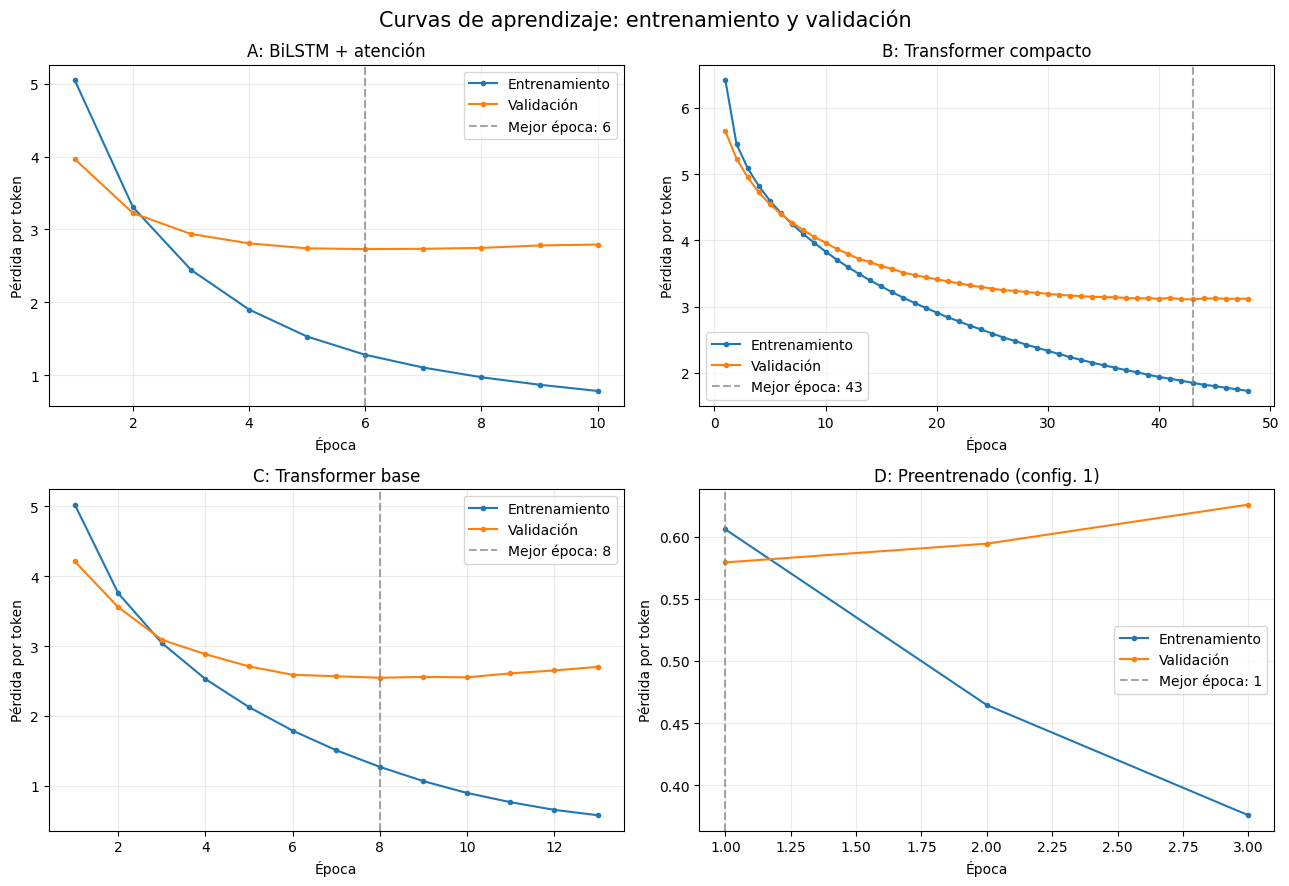

Gráfica guardada en: /content/drive/MyDrive/Proyecto_NLP_NMT/curvas_aprendizaje.png


In [ ]:
import os
import torch
import matplotlib.pyplot as plt

archivos_historial = {
    "A: BiLSTM + atención": "modelo_a_ultimo.pt",
    "B: Transformer compacto": "modelo_b_ultimo.pt",
    "C: Transformer base": "modelo_c_ultimo.pt",
    "D: Preentrenado (config. 1)": "modelo_d_config_1_ultimo.pt"
}

historiales = {}

for nombre, archivo in archivos_historial.items():
    ruta = os.path.join(SAVE_DIR, archivo)

    checkpoint = torch.load(
        ruta,
        map_location="cpu",
        weights_only=True
    )

    if checkpoint["test_audit_id"] != test_hash:
        raise ValueError(f"La auditoría no coincide para {nombre}.")

    historiales[nombre] = checkpoint["history"]

    # Liberar de memoria los pesos y el optimizador del checkpoint.
    del checkpoint


fig, ejes = plt.subplots(2, 2, figsize=(13, 9))
ejes = ejes.flatten()

for eje, (nombre, historial) in zip(ejes, historiales.items()):
    epocas = range(1, len(historial["train_loss"]) + 1)

    eje.plot(
        epocas,
        historial["train_loss"],
        marker="o",
        markersize=3,
        label="Entrenamiento"
    )

    eje.plot(
        epocas,
        historial["val_loss"],
        marker="o",
        markersize=3,
        label="Validación"
    )

    mejor_epoca = (
        min(
            range(len(historial["val_loss"])),
            key=lambda i: historial["val_loss"][i]
        ) + 1
    )

    eje.axvline(
        mejor_epoca,
        color="gray",
        linestyle="--",
        alpha=0.7,
        label=f"Mejor época: {mejor_epoca}"
    )

    eje.set_title(nombre)
    eje.set_xlabel("Época")
    eje.set_ylabel("Pérdida por token")
    eje.grid(alpha=0.25)
    eje.legend()

fig.suptitle(
    "Curvas de aprendizaje: entrenamiento y validación",
    fontsize=15
)

plt.tight_layout()

ruta_grafica = os.path.join(SAVE_DIR, "curvas_aprendizaje.png")
plt.savefig(ruta_grafica, dpi=200, bbox_inches="tight")
plt.show()

print("Gráfica guardada en:", ruta_grafica)

In [ ]:
import os
import json
import time
import math
import torch
import sacrebleu
from torch.utils.data import DataLoader

# Índice → palabra para reconstruir las traducciones.
spa_idx2word = {
    indice: palabra
    for palabra, indice in spa_word2idx.items()
}

# El conjunto de test se usa a partir de aquí solo para evaluación final.
test_dataset = DatasetTraduccion(
    test_pairs,
    eng_word2idx,
    spa_word2idx
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=preparar_lote
)

def calcular_bleu(predicciones, indices):
    """BLEU de corpus, con limpieza simétrica."""
    if not indices:
        return None

    hipotesis = [
        limpiar_texto(predicciones[i])
        for i in indices
    ]

    referencias = [
        limpiar_texto(test_pairs[i][1])
        for i in indices
    ]

    return sacrebleu.corpus_bleu(
        hipotesis,
        [referencias],
        tokenize="13a"
    ).score


def resumir_bleu(predicciones):
    if len(predicciones) != len(test_pairs):
        raise ValueError("La cantidad de predicciones no coincide con test.")

    todos = list(range(len(test_pairs)))

    medios = [
        i for i, (en, es) in enumerate(test_pairs)
        if 8 <= len(en.split()) <= 18
    ]

    largos = [
        i for i, (en, es) in enumerate(test_pairs)
        if len(en.split()) > 18
    ]

    return {
        "bleu_global": calcular_bleu(predicciones, todos),
        "bleu_medios_8_18": calcular_bleu(predicciones, medios),
        "bleu_largos_mas_18": calcular_bleu(predicciones, largos),
        "n_test": len(todos),
        "n_medios": len(medios),
        "n_largos": len(largos),
        "tokenizador_bleu": "13a"
    }


def guardar_resultados(nombre, metricas, predicciones):
    ruta = os.path.join(SAVE_DIR, f"resultados_{nombre}.json")

    resultado = {
        "test_audit_id": test_hash,
        "metricas": metricas,
        "predicciones": predicciones
    }

    with open(ruta, "w", encoding="utf-8") as archivo:
        json.dump(resultado, archivo, ensure_ascii=False, indent=2)

    print("Resultados guardados en:", ruta)


print("Evaluación preparada.")
print("Oraciones de test:", len(test_pairs))
print("Audit ID:", test_hash)

Evaluación preparada.
Oraciones de test: 3642
Audit ID: dbac04ac5648


In [ ]:
import gc

# Liberar la GPU antes de cargar el Modelo A.
if "modelo_d" in globals():
    modelo_d.to("cpu")

if "modelo_c" in globals():
    modelo_c.to("cpu")

gc.collect()
torch.cuda.empty_cache()

# Cargar la mejor época del Modelo A.
checkpoint = torch.load(
    mejor_checkpoint_a,
    map_location="cpu",
    weights_only=True
)

if checkpoint["test_audit_id"] != test_hash:
    raise ValueError("El checkpoint no coincide con la auditoría de test.")

modelo_a.load_state_dict(checkpoint["model_state_dict"])
modelo_a.to(device)
modelo_a.eval()

epoca_elegida_a = checkpoint["epoch"]
del checkpoint

print("Evaluando Modelo A, época seleccionada:", epoca_elegida_a)


@torch.no_grad()
def perdida_test_a():
    suma_perdida = 0.0
    total_tokens = 0

    for origen, destino in test_loader:
        origen = origen.to(device)
        destino = destino.to(device)

        logits = modelo_a(origen, destino)
        etiquetas = destino[:, 1:]

        suma = criterio_a(
            logits.reshape(-1, logits.size(-1)),
            etiquetas.reshape(-1)
        )

        suma_perdida += suma.item()
        total_tokens += (etiquetas != PAD_IDX).sum().item()

    return suma_perdida / total_tokens


@torch.no_grad()
def traducir_a(texto, max_tokens=128):
    origen = convertir_a_indices(texto, eng_word2idx)
    origen = origen.unsqueeze(0).to(device)

    salidas_encoder, hidden, cell, mascara = modelo_a.encoder(origen)

    token = torch.tensor([SOS_IDX], device=device)
    palabras = []

    for _ in range(max_tokens):
        logits, hidden, cell, _ = modelo_a.decoder(
            token,
            hidden,
            cell,
            salidas_encoder,
            mascara
        )

        indice = logits.argmax(dim=1).item()

        if indice == EOS_IDX:
            break

        if indice not in (PAD_IDX, SOS_IDX):
            palabras.append(spa_idx2word.get(indice, UNK))

        token = torch.tensor([indice], device=device)

    return " ".join(palabras)


print("Calculando pérdida de test...")
test_loss_a = perdida_test_a()

print("Generando traducciones...")
predicciones_a = []

if device.type == "cuda":
    torch.cuda.synchronize()

inicio = time.perf_counter()

for i, (ingles, _) in enumerate(test_pairs):
    predicciones_a.append(traducir_a(ingles))

    if (i + 1) % 500 == 0:
        print(f"Traducidas {i + 1}/{len(test_pairs)} oraciones", flush=True)

if device.type == "cuda":
    torch.cuda.synchronize()

tiempo_total = time.perf_counter() - inicio

metricas_a = resumir_bleu(predicciones_a)
metricas_a.update({
    "epoca_seleccionada": epoca_elegida_a,
    "test_loss": test_loss_a,
    "test_perplejidad": math.exp(test_loss_a),
    "parametros_entrenables": parametros_a,
    "tiempo_promedio_epoca_segundos": (
        sum(historiales["A: BiLSTM + atención"]["tiempo_epoca_segundos"])
        / len(historiales["A: BiLSTM + atención"]["tiempo_epoca_segundos"])
    ),
    "latencia_ms_por_oracion": (
        tiempo_total / len(test_pairs) * 1000
    ),
    "decodificacion": "greedy",
    "max_tokens_generados": 128
})

guardar_resultados("modelo_a", metricas_a, predicciones_a)

print("\nMétricas del Modelo A:")
for nombre, valor in metricas_a.items():
    print(f"{nombre}: {valor}")

Evaluando Modelo A, época seleccionada: 6
Calculando pérdida de test...
Generando traducciones...
Traducidas 500/3642 oraciones
Traducidas 1000/3642 oraciones
Traducidas 1500/3642 oraciones
Traducidas 2000/3642 oraciones
Traducidas 2500/3642 oraciones
Traducidas 3000/3642 oraciones
Traducidas 3500/3642 oraciones
Resultados guardados en: /content/drive/MyDrive/Proyecto_NLP_NMT/resultados_modelo_a.json

Métricas del Modelo A:
bleu_global: 23.880660832236124
bleu_medios_8_18: 24.021969252528162
bleu_largos_mas_18: 17.67137744487484
n_test: 3642
n_medios: 3611
n_largos: 31
tokenizador_bleu: 13a
epoca_seleccionada: 6
test_loss: 2.710694560650294
test_perplejidad: 15.0397178842601
parametros_entrenables: 11807978
tiempo_promedio_epoca_segundos: 49.79717850230003
latencia_ms_por_oracion: 8.712054906095258
decodificacion: greedy
max_tokens_generados: 128


In [ ]:
@torch.no_grad()
def perdida_test_transformer(modelo):
    modelo.eval()

    suma_perdida = 0.0
    total_tokens = 0

    for origen, destino in test_loader:
        origen = origen.to(device)
        destino = destino.to(device)

        entrada_decoder = destino[:, :-1]
        etiquetas = destino[:, 1:]

        logits = modelo(origen, entrada_decoder)

        suma = criterio_b(
            logits.reshape(-1, logits.size(-1)),
            etiquetas.reshape(-1)
        )

        suma_perdida += suma.item()
        total_tokens += (etiquetas != PAD_IDX).sum().item()

    return suma_perdida / total_tokens


@torch.no_grad()
def traducir_transformer(modelo, texto, max_tokens=128):
    origen = convertir_a_indices(texto, eng_word2idx)
    origen = origen.unsqueeze(0).to(device)

    # El decoder comienza con <sos>.
    generados = torch.tensor(
        [[SOS_IDX]],
        dtype=torch.long,
        device=device
    )

    palabras = []

    for _ in range(max_tokens):
        logits = modelo(origen, generados)
        siguiente = logits[:, -1, :].argmax(dim=1)

        indice = siguiente.item()

        if indice == EOS_IDX:
            break

        if indice not in (PAD_IDX, SOS_IDX):
            palabras.append(spa_idx2word.get(indice, UNK))

        generados = torch.cat(
            (generados, siguiente.unsqueeze(1)),
            dim=1
        )

    return " ".join(palabras)


def evaluar_transformer(nombre_corto, modelo, ruta_checkpoint, nombre_historial):
    print(f"\nPreparando Modelo {nombre_corto.upper()}...")

    checkpoint = torch.load(
        ruta_checkpoint,
        map_location="cpu",
        weights_only=True
    )

    if checkpoint["test_audit_id"] != test_hash:
        raise ValueError("El checkpoint no coincide con la auditoría.")

    modelo.load_state_dict(checkpoint["model_state_dict"])
    epoca_elegida = checkpoint["epoch"]

    del checkpoint
    gc.collect()
    torch.cuda.empty_cache()

    modelo.to(device)
    modelo.eval()

    parametros = sum(
        p.numel() for p in modelo.parameters()
        if p.requires_grad
    )

    print("Época seleccionada:", epoca_elegida)
    print("Calculando pérdida de test...")

    test_loss = perdida_test_transformer(modelo)

    print("Generando traducciones...")
    predicciones = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    for i, (ingles, _) in enumerate(test_pairs):
        predicciones.append(
            traducir_transformer(modelo, ingles)
        )

        if (i + 1) % 500 == 0:
            print(
                f"Traducidas {i + 1}/{len(test_pairs)} oraciones",
                flush=True
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    tiempo_total = time.perf_counter() - inicio

    tiempos = historiales[nombre_historial]["tiempo_epoca_segundos"]

    metricas = resumir_bleu(predicciones)
    metricas.update({
        "epoca_seleccionada": epoca_elegida,
        "test_loss": test_loss,
        "test_perplejidad": math.exp(test_loss),
        "parametros_entrenables": parametros,
        "tiempo_promedio_epoca_segundos": sum(tiempos) / len(tiempos),
        "latencia_ms_por_oracion": (
            tiempo_total / len(test_pairs) * 1000
        ),
        "decodificacion": "greedy",
        "max_tokens_generados": 128
    })

    guardar_resultados(
        f"modelo_{nombre_corto}",
        metricas,
        predicciones
    )

    print(f"\nMétricas del Modelo {nombre_corto.upper()}:")
    for nombre, valor in metricas.items():
        print(f"{nombre}: {valor}")

    # Liberar la GPU antes del siguiente modelo.
    modelo.to("cpu")
    gc.collect()
    torch.cuda.empty_cache()

    return metricas

In [ ]:
modelo_a.to("cpu")
gc.collect()
torch.cuda.empty_cache()

metricas_b = evaluar_transformer(
    nombre_corto="b",
    modelo=modelo_b,
    ruta_checkpoint=mejor_checkpoint_b,
    nombre_historial="B: Transformer compacto"
)


Preparando Modelo B...
Época seleccionada: 43
Calculando pérdida de test...
Generando traducciones...
Traducidas 500/3642 oraciones
Traducidas 1000/3642 oraciones
Traducidas 1500/3642 oraciones
Traducidas 2000/3642 oraciones
Traducidas 2500/3642 oraciones
Traducidas 3000/3642 oraciones
Traducidas 3500/3642 oraciones
Resultados guardados en: /content/drive/MyDrive/Proyecto_NLP_NMT/resultados_modelo_b.json

Métricas del Modelo B:
bleu_global: 18.433412635271928
bleu_medios_8_18: 18.67122736550288
bleu_largos_mas_18: 7.601248688798014
n_test: 3642
n_medios: 3611
n_largos: 31
tokenizador_bleu: 13a
epoca_seleccionada: 43
test_loss: 3.0999411006825746
test_perplejidad: 22.196643875765943
parametros_entrenables: 5971434
tiempo_promedio_epoca_segundos: 22.73321853260417
latencia_ms_por_oracion: 40.89990208347031
decodificacion: greedy
max_tokens_generados: 128


In [ ]:
metricas_c = evaluar_transformer(
    nombre_corto="c",
    modelo=modelo_c,
    ruta_checkpoint=mejor_checkpoint_c,
    nombre_historial="C: Transformer base"
)


Preparando Modelo C...
Época seleccionada: 8
Calculando pérdida de test...
Generando traducciones...
Traducidas 500/3642 oraciones
Traducidas 1000/3642 oraciones
Traducidas 1500/3642 oraciones
Traducidas 2000/3642 oraciones
Traducidas 2500/3642 oraciones
Traducidas 3000/3642 oraciones
Traducidas 3500/3642 oraciones
Resultados guardados en: /content/drive/MyDrive/Proyecto_NLP_NMT/resultados_modelo_c.json

Métricas del Modelo C:
bleu_global: 24.73612855209327
bleu_medios_8_18: 25.040723689286203
bleu_largos_mas_18: 9.741716931863547
n_test: 3642
n_medios: 3611
n_largos: 31
tokenizador_bleu: 13a
epoca_seleccionada: 8
test_loss: 2.5391169995420806
test_perplejidad: 12.668479757210878
parametros_entrenables: 64275818
tiempo_promedio_epoca_segundos: 280.74197628499996
latencia_ms_por_oracion: 116.02952066117521
decodificacion: greedy
max_tokens_generados: 128


In [ ]:
import gc

# Liberar GPU antes de evaluar el Modelo D.
modelo_a.to("cpu")
modelo_b.to("cpu")
modelo_c.to("cpu")

gc.collect()
torch.cuda.empty_cache()

ruta_mejor_d = os.path.join(
    SAVE_DIR,
    "modelo_d_config_1_mejor.pt"
)

checkpoint = torch.load(
    ruta_mejor_d,
    map_location="cpu",
    weights_only=True
)

if checkpoint["test_audit_id"] != test_hash:
    raise ValueError("El checkpoint no coincide con la auditoría de test.")

if checkpoint["model_name"] != NOMBRE_MODELO_D:
    raise ValueError("El checkpoint corresponde a otro modelo.")

modelo_d.load_state_dict(checkpoint["model_state_dict"])
epoca_elegida_d = checkpoint["epoch"]

del checkpoint
gc.collect()

modelo_d.to(device)
modelo_d.eval()

print("Evaluando Modelo D, época seleccionada:", epoca_elegida_d)

# Preparar test con el tokenizador del modelo preentrenado.
test_dataset_d = DatasetModeloD(test_pairs, tokenizer_d)

longitud_max_test_d = max(
    max(len(x) for x in test_dataset_d.entradas),
    max(len(x) for x in test_dataset_d.salidas)
)

if longitud_max_test_d > modelo_d.config.max_position_embeddings:
    raise ValueError(
        "Hay secuencias de test que superan el límite del modelo. "
        "Compárteme este error antes de continuar."
    )

test_loader_d = DataLoader(
    test_dataset_d,
    batch_size=8,
    shuffle=False,
    collate_fn=preparar_lote_d
)

print("Calculando pérdida de test...")
test_loss_d = ejecutar_epoca_d(
    modelo_d,
    test_loader_d
)


@torch.no_grad()
def traducir_d(texto, max_tokens=128):
    entradas = tokenizer_d(
        texto,
        return_tensors="pt",
        truncation=False
    ).to(device)

    salida = modelo_d.generate(
        **entradas,
        do_sample=False,
        num_beams=1,
        max_new_tokens=max_tokens
    )

    return tokenizer_d.decode(
        salida[0],
        skip_special_tokens=True
    )


print("Generando traducciones...")
predicciones_d = []

if device.type == "cuda":
    torch.cuda.synchronize()

inicio = time.perf_counter()

for i, (ingles, _) in enumerate(test_pairs):
    predicciones_d.append(traducir_d(ingles))

    if (i + 1) % 500 == 0:
        print(
            f"Traducidas {i + 1}/{len(test_pairs)} oraciones",
            flush=True
        )

if device.type == "cuda":
    torch.cuda.synchronize()

tiempo_total = time.perf_counter() - inicio

tiempos_d = historiales[
    "D: Preentrenado (config. 1)"
]["tiempo_epoca_segundos"]

metricas_d = resumir_bleu(predicciones_d)
metricas_d.update({
    "epoca_seleccionada": epoca_elegida_d,
    "test_loss": test_loss_d,
    "test_perplejidad": math.exp(test_loss_d),
    "parametros_entrenables": parametros_d,
    "tiempo_promedio_epoca_segundos": (
        sum(tiempos_d) / len(tiempos_d)
    ),
    "latencia_ms_por_oracion": (
        tiempo_total / len(test_pairs) * 1000
    ),
    "decodificacion": "greedy",
    "max_tokens_generados": 128
})

guardar_resultados(
    "modelo_d",
    metricas_d,
    predicciones_d
)

print("\nMétricas del Modelo D:")
for nombre, valor in metricas_d.items():
    print(f"{nombre}: {valor}")

modelo_d.to("cpu")
gc.collect()
torch.cuda.empty_cache()

Evaluando Modelo D, época seleccionada: 1
Calculando pérdida de test...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generando traducciones...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Traducidas 500/3642 oraciones


[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

... (9 outputs left out)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Traducidas 3500/3642 oraciones


[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Resultados guardados en: /content/drive/MyDrive/Proyecto_NLP_NMT/resultados_modelo_d.json

Métricas del Modelo D:
bleu_global: 57.39975620928978
bleu_medios_8_18: 57.29727203125778
bleu_largos_mas_18: 60.593015021898864
n_test: 3642
n_medios: 3611
n_largos: 31
tokenizador_bleu: 13a
epoca_seleccionada: 1
test_loss: 0.5559178596335888
test_perplejidad: 1.7435405760759364
parametros_entrenables: 77943296
tiempo_promedio_epoca_segundos: 292.9897935649997
latencia_ms_por_oracion: 109.60314759143318
decodificacion: greedy
max_tokens_generados: 128


In [ ]:
import os
import json

nombres_modelos = {
    "A: BiLSTM + atención": "modelo_a",
    "B: Transformer compacto": "modelo_b",
    "C: Transformer base": "modelo_c",
    "D: Preentrenado": "modelo_d"
}

resultados = {}

for nombre, archivo in nombres_modelos.items():
    ruta = os.path.join(SAVE_DIR, f"resultados_{archivo}.json")

    with open(ruta, "r", encoding="utf-8") as f:
        resultado = json.load(f)

    if resultado["test_audit_id"] != test_hash:
        raise ValueError(f"La auditoría no coincide para {nombre}.")

    resultados[nombre] = resultado

print("Resultados recuperados:", list(resultados.keys()))

Resultados recuperados: ['A: BiLSTM + atención', 'B: Transformer compacto', 'C: Transformer base', 'D: Preentrenado']


In [8]:
import json
import math
import os
import re
import time
import unicodedata

import sacrebleu
import torch
from torch.utils.data import DataLoader
from transformers import (
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq
)
from transformers.utils import logging as hf_logging


# Verificar que se utiliza la partición de test del proyecto.
AUDIT_ID_ESPERADO = "dbac04ac5648"

if test_hash != AUDIT_ID_ESPERADO:
    raise ValueError(
        f"El Audit ID actual es {test_hash}; se esperaba "
        f"{AUDIT_ID_ESPERADO}. Revisa la copia de spa.txt."
    )

if not test_pairs:
    raise ValueError("El conjunto de test está vacío.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
nombre_modelo = "Helsinki-NLP/opus-mt-en-es"

print("Dispositivo:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Audit ID:", test_hash)

# Cargar el modelo original, sin ajuste fino.
print("\nCargando modelo y tokenizador...")
hf_logging.set_verbosity_error()

tokenizer_zero = AutoTokenizer.from_pretrained(nombre_modelo)
modelo_zero = AutoModelForSeq2SeqLM.from_pretrained(nombre_modelo).to(device)
modelo_zero.eval()

parametros_zero = sum(
    parametro.numel()
    for parametro in modelo_zero.parameters()
    if parametro.requires_grad
)


# Preparar las referencias para calcular la pérdida de test.
print("Preparando datos de test...")

datos_test_zero = []

for ingles, espanol in test_pairs:
    entrada = tokenizer_zero(ingles, truncation=False)
    salida = tokenizer_zero(text_target=espanol, truncation=False)

    datos_test_zero.append({
        "input_ids": entrada["input_ids"],
        "attention_mask": entrada["attention_mask"],
        "labels": salida["input_ids"]
    })

collator_zero = DataCollatorForSeq2Seq(
    tokenizer=tokenizer_zero,
    model=modelo_zero,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt"
)

test_loader_zero = DataLoader(
    datos_test_zero,
    batch_size=8,
    shuffle=False,
    collate_fn=collator_zero
)


# Calcular pérdida promedio por token y perplejidad.
print("Calculando pérdida de test...")

perdida_total = 0.0
tokens_totales = 0

with torch.no_grad():
    for lote in test_loader_zero:
        lote = {
            clave: valor.to(device)
            for clave, valor in lote.items()
        }

        resultado = modelo_zero(**lote)
        num_tokens = (lote["labels"] != -100).sum().item()

        perdida_total += resultado.loss.item() * num_tokens
        tokens_totales += num_tokens

test_loss_zero = perdida_total / tokens_totales
perplejidad_zero = math.exp(test_loss_zero)


# Generar una traducción a la vez y medir la latencia.
print("Traduciendo oraciones de test...")

predicciones_zero = []

if device.type == "cuda":
    torch.cuda.synchronize()

inicio = time.perf_counter()

with torch.no_grad():
    for i, (ingles, _) in enumerate(test_pairs):
        entradas = tokenizer_zero(
            ingles,
            return_tensors="pt",
            truncation=False
        ).to(device)

        salida = modelo_zero.generate(
            **entradas,
            do_sample=False,
            num_beams=1,
            max_new_tokens=128
        )

        predicciones_zero.append(
            tokenizer_zero.decode(
                salida[0],
                skip_special_tokens=True
            )
        )

        if (i + 1) % 500 == 0:
            print(f"Traducidas {i + 1}/{len(test_pairs)}", flush=True)

if device.type == "cuda":
    torch.cuda.synchronize()

latencia_ms = (time.perf_counter() - inicio) / len(test_pairs) * 1000


# Usar la misma limpieza aplicada en la evaluación de A, B, C y D.
def limpiar_para_bleu(texto):
    texto = texto.lower().strip()
    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(
        caracter for caracter in texto
        if unicodedata.category(caracter) != "Mn"
    )
    texto = re.sub(r"[^\w\s]", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()


def bleu_de_indices(indices):
    if not indices:
        return None

    hipotesis = [
        limpiar_para_bleu(predicciones_zero[i])
        for i in indices
    ]

    referencias = [
        limpiar_para_bleu(test_pairs[i][1])
        for i in indices
    ]

    return sacrebleu.corpus_bleu(
        hipotesis,
        [referencias],
        tokenize="13a"
    ).score


todos = list(range(len(test_pairs)))

medios = [
    i for i, (ingles, _) in enumerate(test_pairs)
    if 8 <= len(ingles.split()) <= 18
]

largos = [
    i for i, (ingles, _) in enumerate(test_pairs)
    if len(ingles.split()) > 18
]

metricas_zero = {
    "bleu_global": bleu_de_indices(todos),
    "bleu_medios_8_18": bleu_de_indices(medios),
    "bleu_largos_mas_18": bleu_de_indices(largos),
    "test_loss": test_loss_zero,
    "test_perplejidad": perplejidad_zero,
    "parametros_entrenables": parametros_zero,
    "latencia_ms_por_oracion": latencia_ms,
    "dispositivo": str(device),
    "n_test": len(todos),
    "n_medios": len(medios),
    "n_largos": len(largos),
    "test_audit_id": test_hash,
    "modelo": nombre_modelo,
    "ajuste_fino": False,
    "decodificacion": "greedy",
    "max_tokens_generados": 128
}

# Guardar métricas y traducciones en Drive.
ruta = os.path.join(SAVE_DIR, "resultados_d_sin_ajuste.json")

with open(ruta, "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "metricas": metricas_zero,
            "predicciones": predicciones_zero
        },
        archivo,
        ensure_ascii=False,
        indent=2
    )

print("\nResultados del modelo sin ajuste fino:")
print(f"BLEU global: {metricas_zero['bleu_global']:.2f}")
print(f"BLEU 8–18 palabras: {metricas_zero['bleu_medios_8_18']:.2f}")
print(f"BLEU más de 18 palabras: {metricas_zero['bleu_largos_mas_18']:.2f}")
print(f"Pérdida en test: {test_loss_zero:.4f}")
print(f"Perplejidad en test: {perplejidad_zero:.2f}")
print(f"Parámetros entrenables: {parametros_zero:,}")
print(f"Latencia por oración: {latencia_ms:.2f} ms")
print("Resultados y traducciones guardados en:", ruta)

Dispositivo: cuda
GPU: Tesla T4
Audit ID: dbac04ac5648

Cargando modelo y tokenizador...


config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  312MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Preparando datos de test...
Calculando pérdida de test...
Traduciendo oraciones de test...
Traducidas 500/3642
Traducidas 1000/3642
Traducidas 1500/3642
Traducidas 2000/3642
Traducidas 2500/3642
Traducidas 3000/3642
Traducidas 3500/3642

Resultados del modelo sin ajuste fino:
BLEU global: 55.57
BLEU 8–18 palabras: 55.54
BLEU más de 18 palabras: 56.90
Pérdida en test: 0.6796
Perplejidad en test: 1.97
Parámetros entrenables: 77,943,296
Latencia por oración: 88.55 ms
Resultados y traducciones guardados en: /content/drive/MyDrive/Proyecto_NLP_NMT/resultados_d_sin_ajuste.json


In [9]:
import os
import json
import pandas as pd

nombres_modelos = {
    "A: BiLSTM + atención": "modelo_a",
    "B: Transformer compacto": "modelo_b",
    "C: Transformer base": "modelo_c",
    "D: Preentrenado": "modelo_d"
}

resultados = {}

for nombre, archivo in nombres_modelos.items():
    ruta = os.path.join(SAVE_DIR, f"resultados_{archivo}.json")

    with open(ruta, "r", encoding="utf-8") as f:
        resultado = json.load(f)

    if resultado["test_audit_id"] != test_hash:
        raise ValueError(f"La auditoría no coincide para {nombre}.")

    resultados[nombre] = resultado


filas = {
    "BLEU global": "bleu_global",
    "BLEU 8–18 palabras": "bleu_medios_8_18",
    "BLEU > 18 palabras": "bleu_largos_mas_18",
    "Pérdida en test": "test_loss",
    "Perplejidad en test": "test_perplejidad",
    "Parámetros entrenables": "parametros_entrenables",
    "Tiempo promedio por época (s)": "tiempo_promedio_epoca_segundos",
    "Latencia por oración (ms)": "latencia_ms_por_oracion",
    "Época seleccionada": "epoca_seleccionada"
}

tabla = pd.DataFrame({
    nombre: {
        etiqueta: resultado["metricas"][clave]
        for etiqueta, clave in filas.items()
    }
    for nombre, resultado in resultados.items()
})

# Incorporar el modelo preentrenado antes del ajuste fino.
ruta_zero = os.path.join(SAVE_DIR, "resultados_d_sin_ajuste.json")

with open(ruta_zero, "r", encoding="utf-8") as archivo:
    resultado_zero = json.load(archivo)

metricas_zero = resultado_zero["metricas"]

if metricas_zero["test_audit_id"] != test_hash:
    raise ValueError("La auditoría del modelo sin ajuste no coincide.")

tabla["D: sin ajuste fino"] = pd.Series({
    "BLEU global": metricas_zero["bleu_global"],
    "BLEU 8–18 palabras": metricas_zero["bleu_medios_8_18"],
    "BLEU > 18 palabras": metricas_zero["bleu_largos_mas_18"],
    "Pérdida en test": metricas_zero["test_loss"],
    "Perplejidad en test": metricas_zero["test_perplejidad"],
    "Parámetros entrenables": metricas_zero["parametros_entrenables"],
    "Latencia por oración (ms)": metricas_zero["latencia_ms_por_oracion"],
})

display(tabla.round(2))

ruta_tabla = os.path.join(SAVE_DIR, "tabla_comparativa_test.csv")
tabla.to_csv(ruta_tabla, encoding="utf-8-sig")

print("Tabla guardada en:", ruta_tabla)
print("Audit ID:", test_hash)
print("Ejemplos en test:", len(test_pairs))

,A: BiLSTM + atención,B: Transformer compacto,C: Transformer base,D: Preentrenado,D: sin ajuste fino
BLEU global,23.88,18.43,24.74,57.40,55.57
BLEU 8–18 palabras,24.02,18.67,25.04,57.30,55.54
BLEU > 18 palabras,17.67,7.60,9.74,60.59,56.90
Pérdida en test,2.71,3.10,2.54,0.56,0.68
Perplejidad en test,15.04,22.20,12.67,1.74,1.97
Parámetros entrenables,11807978.00,5971434.00,64275818.00,77943296.00,77943296.00
Tiempo promedio por época (s),49.80,22.73,280.74,292.99,NaN
Latencia por oración (ms),8.71,40.90,116.03,109.60,88.55
Época seleccionada,6.00,43.00,8.00,1.00,NaN


Tabla guardada en: /content/drive/MyDrive/Proyecto_NLP_NMT/tabla_comparativa_test.csv
Audit ID: dbac04ac5648
Ejemplos en test: 3642


In [ ]:
indices_medios = [
    i for i, (en, es) in enumerate(test_pairs)
    if 8 <= len(en.split()) <= 18
]

indices_complejos = [
    i for i, (en, es) in enumerate(test_pairs)
    if len(en.split()) > 20
]

if len(indices_medios) < 3 or len(indices_complejos) < 2:
    raise ValueError(
        "No hay suficientes ejemplos para la selección solicitada."
    )

# Selección determinista, sin elegir por calidad de traducción.
indices_elegidos = indices_medios[:3] + indices_complejos[:2]

ejemplos_analisis = []

for numero, indice in enumerate(indices_elegidos, start=1):
    ingles, referencia = test_pairs[indice]

    ejemplo = {
        "ejemplo": numero,
        "indice_test": indice,
        "palabras_ingles": len(ingles.split()),
        "ingles": ingles,
        "referencia": referencia
    }

    print(f"\n{'=' * 70}")
    print(
        f"EJEMPLO {numero} | Índice de test: {indice} | "
        f"Palabras en inglés: {len(ingles.split())}"
    )
    print("Inglés:    ", ingles)
    print("Referencia:", referencia)

    for nombre, resultado in resultados.items():
        traduccion = resultado["predicciones"][indice]
        ejemplo[nombre] = traduccion
        print(f"{nombre}: {traduccion}")

    ejemplos_analisis.append(ejemplo)


ruta_ejemplos = os.path.join(SAVE_DIR, "ejemplos_analisis.json")

with open(ruta_ejemplos, "w", encoding="utf-8") as f:
    json.dump(
        {
            "test_audit_id": test_hash,
            "ejemplos": ejemplos_analisis
        },
        f,
        ensure_ascii=False,
        indent=2
    )

print("\nEjemplos guardados en:", ruta_ejemplos)


EJEMPLO 1 | Índice de test: 0 | Palabras en inglés: 8
Inglés:     You have to write the correct zip code.
Referencia: Debes poner el código postal correcto.
A: BiLSTM + atención: tienes que escribir el futuro de nieve
B: Transformer compacto: tienes que escribir el fuego lento
C: Transformer base: tienes que escribir el llamado para escribir
D: Preentrenado: Tienes que escribir el código postal correcto.

EJEMPLO 2 | Índice de test: 1 | Palabras en inglés: 8
Inglés:     You can't make an omelet without breaking eggs.
Referencia: No podés hacer un omelet sin romper los huevos.
A: BiLSTM + atención: no puedes hacer un omelet sin quebrar huevos
B: Transformer compacto: no puedes hacer un omelet sin quebrar huevos
C: Transformer base: no puedes hacer un omelet sin huevos
D: Preentrenado: No puedes hacer un omelet sin quebrar huevos.

EJEMPLO 3 | Índice de test: 2 | Palabras en inglés: 8
Inglés:     My mother is sick with a bad cold.
Referencia: Mi madre ha pillado un terrible resfriado.
A

Oración: You have to write the correct zip code.
Referencia: Debes poner el código postal correcto.


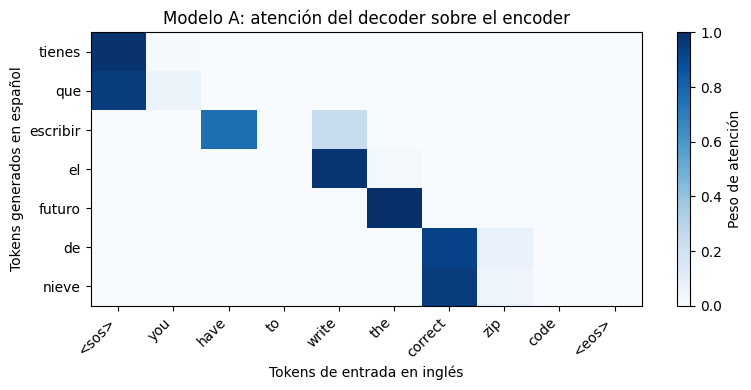

Mapa guardado en: /content/drive/MyDrive/Proyecto_NLP_NMT/mapa_atencion_modelo_a.png


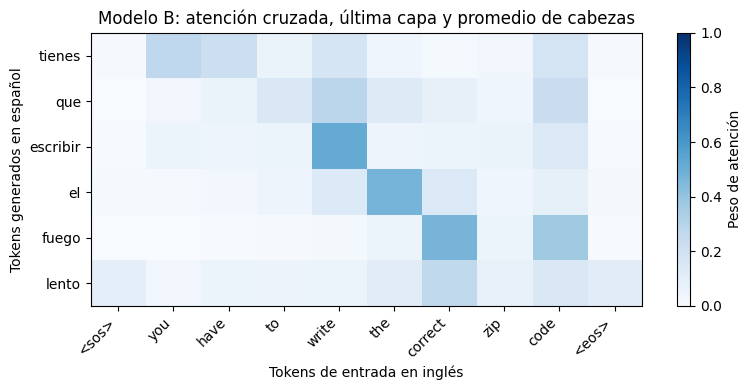

Mapa guardado en: /content/drive/MyDrive/Proyecto_NLP_NMT/mapa_atencion_modelo_b.png


In [ ]:
import os
import gc
import numpy as np
import matplotlib.pyplot as plt
import torch

# Usaremos la misma oración para ambos mapas.
indice_mapa = 0
frase_mapa = test_pairs[indice_mapa][0]

print("Oración:", frase_mapa)
print("Referencia:", test_pairs[indice_mapa][1])

eng_idx2word = {
    indice: palabra
    for palabra, indice in eng_word2idx.items()
}


def cargar_mejor_modelo(modelo, ruta):
    checkpoint = torch.load(
        ruta,
        map_location="cpu",
        weights_only=True
    )

    if checkpoint["test_audit_id"] != test_hash:
        raise ValueError("La auditoría del checkpoint no coincide.")

    modelo.load_state_dict(checkpoint["model_state_dict"])

    del checkpoint
    gc.collect()
    torch.cuda.empty_cache()

    modelo.to(device)
    modelo.eval()


def etiquetas_origen(texto):
    indices = convertir_a_indices(texto, eng_word2idx).tolist()
    return [eng_idx2word.get(i, UNK) for i in indices]


@torch.no_grad()
def atencion_modelo_a(texto, max_tokens=128):
    origen = convertir_a_indices(texto, eng_word2idx)
    origen = origen.unsqueeze(0).to(device)

    salidas_encoder, hidden, cell, mascara = modelo_a.encoder(origen)

    token = torch.tensor([SOS_IDX], device=device)

    palabras_salida = []
    filas_atencion = []

    for _ in range(max_tokens):
        logits, hidden, cell, atencion = modelo_a.decoder(
            token,
            hidden,
            cell,
            salidas_encoder,
            mascara
        )

        indice = logits.argmax(dim=1).item()

        if indice == EOS_IDX:
            break

        if indice not in (PAD_IDX, SOS_IDX):
            palabras_salida.append(spa_idx2word.get(indice, UNK))
            filas_atencion.append(
                atencion[0].detach().cpu().numpy()
            )

        token = torch.tensor([indice], device=device)

    return palabras_salida, np.array(filas_atencion)


@torch.no_grad()
def atencion_modelo_b(texto, max_tokens=128):
    origen = convertir_a_indices(texto, eng_word2idx)
    origen = origen.unsqueeze(0).to(device)

    generados = torch.tensor(
        [[SOS_IDX]],
        dtype=torch.long,
        device=device
    )

    palabras_salida = []
    filas_atencion = []

    for _ in range(max_tokens):
        logits = modelo_b(
            origen,
            generados,
            guardar_atencion=True
        )

        indice = logits[:, -1, :].argmax(dim=1).item()

        if indice == EOS_IDX:
            break

        if indice not in (PAD_IDX, SOS_IDX):
            # Última capa del decoder.
            # Forma: [batch, cabezas, destino, origen].
            pesos = modelo_b.decoders[-1].ultima_atencion

            # Promediar cabezas para el último token del decoder.
            pesos_promedio = pesos[0, :, -1, :].mean(dim=0)

            palabras_salida.append(spa_idx2word.get(indice, UNK))
            filas_atencion.append(
                pesos_promedio.detach().cpu().numpy()
            )

        siguiente = torch.tensor(
            [[indice]],
            dtype=torch.long,
            device=device
        )

        generados = torch.cat((generados, siguiente), dim=1)

    return palabras_salida, np.array(filas_atencion)


def dibujar_mapa(matriz, entrada, salida, titulo, archivo):
    if len(salida) == 0:
        raise ValueError("El modelo no generó palabras para el mapa.")

    alto = max(4, len(salida) * 0.48)
    ancho = max(8, len(entrada) * 0.7)

    fig, eje = plt.subplots(figsize=(ancho, alto))

    imagen = eje.imshow(
        matriz,
        aspect="auto",
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    eje.set_xticks(range(len(entrada)))
    eje.set_xticklabels(entrada, rotation=45, ha="right")

    eje.set_yticks(range(len(salida)))
    eje.set_yticklabels(salida)

    eje.set_xlabel("Tokens de entrada en inglés")
    eje.set_ylabel("Tokens generados en español")
    eje.set_title(titulo)

    fig.colorbar(imagen, ax=eje, label="Peso de atención")
    plt.tight_layout()

    ruta = os.path.join(SAVE_DIR, archivo)
    plt.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()

    print("Mapa guardado en:", ruta)


# Asegurar que los demás modelos no ocupen GPU.
for nombre in ("modelo_a", "modelo_b", "modelo_c", "modelo_d"):
    if nombre in globals():
        globals()[nombre].to("cpu")

gc.collect()
torch.cuda.empty_cache()

# Mapa del Modelo A.
cargar_mejor_modelo(modelo_a, mejor_checkpoint_a)

salida_a, matriz_a = atencion_modelo_a(frase_mapa)

dibujar_mapa(
    matriz_a,
    etiquetas_origen(frase_mapa),
    salida_a,
    "Modelo A: atención del decoder sobre el encoder",
    "mapa_atencion_modelo_a.png"
)

modelo_a.to("cpu")
gc.collect()
torch.cuda.empty_cache()

# Mapa del Modelo B.
cargar_mejor_modelo(modelo_b, mejor_checkpoint_b)

salida_b, matriz_b = atencion_modelo_b(frase_mapa)

dibujar_mapa(
    matriz_b,
    etiquetas_origen(frase_mapa),
    salida_b,
    "Modelo B: atención cruzada, última capa y promedio de cabezas",
    "mapa_atencion_modelo_b.png"
)

modelo_b.to("cpu")
gc.collect()
torch.cuda.empty_cache()